## BT4222 · MLP Ranking Model (`mlp_model.ipynb`)

Hybrid MLP that scores every (user, candidate article) pair in an impression and ranks the slate. It follows this structure: input groups → 64-d projections → concatenation → 128 → 64 → 32 → score, listwise softmax loss.

**Cold-user simulation.** Every training run hides the history of a share of warm users (`COLD_SIM_RATE`), so the model also learns to rank for users without history. The reasoning and the imputed cold-user inputs are in Section 2.1.

**Feature selection by ablation.** The full model now includes the two optional features from the past project (`habit_score`, `diversity_ratio`). Section 7 retrains the model with each optional feature and each feature group removed, drops every component whose removal does not hurt validation nDCG@5, retrains the reduced model, and keeps whichever of the full or reduced model is better **on validation**. The test set is only used after the choice is made.

## 0. Setup & configuration

In [1]:
import os, sys, json, time, copy, random
import numpy as np
import pandas as pd
from scipy.stats import rankdata

from google.colab import drive

drive.mount('/content/drive')

FEATURE_DIR = "/content/drive/MyDrive/Y4S1/BT4222/MLP/"
OUT_DIR = "/content/drive/MyDrive/Y4S1/BT4222/mlp_out/"
MODEL_NAME = 'mlp'

# ── Hyperparameters  ─
SEED = 42
EMBED_DIM = 64
CAT_DIM = 32
HIDDEN = [128, 64, 32]
DROPOUT = 0.2
ID_DROPOUT = 0.1
LR = 1e-3
WEIGHT_DECAY = 1e-5
BATCH_SIZE = 32
EVAL_BATCH = 128
MAX_EPOCHS = 8
PATIENCE = 2
SELECT_METRIC = 'nDCG@5'           # early stopping / model selection on validation

# ── Evaluation & export ──────────────────────────────────────────────────────
NDCG_KS = (5, 10)
RECALL_KS = (5, 10)
TOPK_EXPORT = 10

# ── Feature groups & optional features (the starting "full" model uses everything) ─
USE_GROUPS = {'article': True, 'popularity': True, 'user': True, 'user_x_article': True, 'context': True}
USE_OPTIONAL = {'diversity_ratio': True, 'habit_score': True}   # features from past project

# ── Ablation & model selection (Section 7) ───────────────────────────────────
RUN_ABLATION = True                # one retrain per ablation config (~8 runs): use a GPU runtime
ABLATION_EPOCHS = MAX_EPOCHS       # same budget + early stopping as the full model, so runs are comparable
ABLATION_SEEDS = [SEED]          # e.g. [42, 7, 2024] to average out run-to-run noise (3x slower)
DROP_TOLERANCE = 0.001             # drop a component if removing it changes val nDCG@5 by >= -0.001
REPORT_TEST_FOR_ALL = True         # also report test metrics of every ablation config (selection uses val only)
RUN_PERMUTATION_IMPORTANCE = True

# ── Cold-user simulation (prepared in Section 2.1, applied to every training run in Sections 6-7) ─
COLD_SIM_RATE = 0.15               # share of warm training groups shown to the model as cold users; 0 = off
COMPARE_NO_SIM = True              # Section 8.1: also report the selected config trained WITHOUT simulation

SPLITS = ['train', 'val', 'test']
os.makedirs(OUT_DIR, exist_ok=True)
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 20)
print('FEATURE_DIR =', FEATURE_DIR, '\nOUT_DIR     =', OUT_DIR)


def load_table(name):
    base = os.path.join(FEATURE_DIR, name)
    return pd.read_parquet(base + '.parquet') if os.path.exists(base + '.parquet') else pd.read_pickle(base + '.pkl')


def save_table(df, name):
    path = os.path.join(OUT_DIR, name)
    try:
        df.to_parquet(path + '.parquet', index=False)
    except ImportError:
        df.to_pickle(path + '.pkl')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
FEATURE_DIR = /content/drive/MyDrive/Y4S1/BT4222/MLP/ 
OUT_DIR     = /content/drive/MyDrive/Y4S1/BT4222/mlp_out/


## 1. Load engineered features

In [2]:
with open(os.path.join(FEATURE_DIR, 'feature_meta.json')) as f:
    meta = json.load(f)
dims = meta['dims']
N_ART, N_CAT, N_SUBCAT = dims['n_articles'], dims['n_cat'], dims['n_subcat']
SPARSE_MAX = meta['cold_start']['sparse_user_max']

articles = load_table('articles')
content_emb = np.load(os.path.join(FEATURE_DIR, 'article_content_emb.npy')).astype(np.float32)
kg_emb = np.load(os.path.join(FEATURE_DIR, 'kg_entity_emb.npy')).astype(np.float32)
has_kg = np.zeros(N_ART, np.float32);  has_kg[articles.news_idx.values] = articles.has_kg_entity.values
art_cat = np.zeros(N_ART, np.int64);   art_cat[articles.news_idx.values] = articles.category_idx.values
art_subcat = np.zeros(N_ART, np.int64); art_subcat[articles.news_idx.values] = articles.subcategory_idx.values
news_ids = np.empty(N_ART, dtype=object); news_ids[0] = '<PAD>'; news_ids[articles.news_idx.values] = articles.news_id.values

profiles = load_table('user_profiles').sort_values('profile_idx').reset_index(drop=True)
user_emb = np.load(os.path.join(FEATURE_DIR, 'user_history_emb.npy')).astype(np.float32)
user_aff = np.load(os.path.join(FEATURE_DIR, 'user_category_affinity.npy')).astype(np.float32)

data = {s: {'imp': load_table(f'{s}_impressions'), 'groups': load_table(f'{s}_groups'),
            'cands': load_table(f'{s}_candidates')} for s in SPLITS}
for s in SPLITS:
    print(f"{s:5s}: {len(data[s]['groups']):>8,} groups | {len(data[s]['cands']):>10,} candidates | "
          f"days {[int(x) for x in sorted(data[s]['imp'].day.unique())]}")
print('Split:', meta['split']['scheme'], '| negatives:', meta['negative_sampling']['train'])

train:  189,519 groups |    906,625 candidates | days [0, 1, 2, 3, 4]
val  :   30,270 groups |  1,222,429 candidates | days [5]
test :   73,152 groups |  2,740,998 candidates | days [6]
Split: 5-1-1 by calendar day | negatives: per positive, up to 4 negatives from same impression, no replacement, seed 42; short groups masked (no repeats); impressions without negatives dropped


## 2. Input preparation
Feature lists come from `feature_meta.json`. Continuous inputs are standardised with **training** mean/std; binary flags are left as 0/1. Each split becomes flat arrays (one row per candidate) plus per-group offsets, so variable-length val/test slates are padded only per batch.

The arrays always hold **every** feature, including the optional ones. Which features the model actually uses is decided by a *config* (`groups` switched on + `drop` = features removed), so ablation runs reuse the same arrays.

In [3]:
F = meta['features']
POP_COLS = F['popularity']                                   # hist_ctr, log_exposure, is_cold_article
INTER_COLS = F['user_x_article']                             # 6 user x article features
CAND_COLS = POP_COLS + INTER_COLS
OPTIONAL_USER = F['optional']['user']                        # diversity_ratio
OPTIONAL_CTX = F['optional']['context']                      # habit_score
USER_COLS = F['user']['scalar'] + OPTIONAL_USER              # all user scalars stored in user_x
CTX_COLS = F['context'] + OPTIONAL_CTX                       # all context features stored in ctx_x
OPTIONAL_FEATURES = OPTIONAL_USER + OPTIONAL_CTX
BINARY = {'is_cold_article', 'category_match', 'has_history'}

used = set(CAND_COLS + USER_COLS + CTX_COLS) | {'article_content_emb', 'kg_entity_emb', 'category_idx', 'subcategory_idx'}
assert not used & set(meta['excluded_features']), 'contract: excluded feature in use'


def make_config(name, groups=None, drop=()):
    """A model config = which groups are on + which individual features are dropped."""
    return {'name': name, 'groups': dict(groups or USE_GROUPS), 'drop': sorted(set(drop))}


def active_features(cfg):
    """Feature names actually fed to the model under cfg, per input block."""
    keep = lambda cols: [c for c in cols if c not in cfg['drop']]
    g = cfg['groups']
    return {'popularity': keep(POP_COLS) if g['popularity'] else [],
            'user_x_article': keep(INTER_COLS) if g['user_x_article'] else [],
            'user': keep(USER_COLS) if g['user'] else [],
            'context': keep(CTX_COLS) if g['context'] else []}


FULL_CFG = make_config('full', USE_GROUPS, drop=[f for f in OPTIONAL_FEATURES if not USE_OPTIONAL.get(f)])
for block, cols in active_features(FULL_CFG).items():
    print(f'{block:15s}: {cols}')

# standardisation stats from the training split only
tr_c = data['train']['cands']
tr_prof = data['train']['imp'].set_index('impression_id').loc[data['train']['groups'].impression_id, 'profile_idx'].values
cand_mu = {c: (0.0 if c in BINARY else float(tr_c[c].mean())) for c in CAND_COLS}
cand_sd = {c: (1.0 if c in BINARY else float(tr_c[c].std() or 1.0)) for c in CAND_COLS}
user_mu = {c: (0.0 if c in BINARY else float(profiles[c].values[tr_prof].mean())) for c in USER_COLS}
user_sd = {c: (1.0 if c in BINARY else float(profiles[c].values[tr_prof].std() or 1.0)) for c in USER_COLS}
ctx_mu = {c: float(data['train']['imp'][c].mean()) if c == 'habit_score' else 0.0 for c in CTX_COLS}
ctx_sd = {c: float(data['train']['imp'][c].std() or 1.0) if c == 'habit_score' else 1.0 for c in CTX_COLS}

user_x_all = np.stack([(profiles[c].values - user_mu[c]) / user_sd[c] for c in USER_COLS], 1).astype(np.float32)


def assemble(split):
    d = data[split]
    g = d['groups'].sort_values('group_id').reset_index(drop=True)
    c = d['cands'].sort_values(['group_id', 'slot']).reset_index(drop=True)
    imp = d['imp'].set_index('impression_id').loc[g.impression_id]
    start = np.concatenate([[0], np.cumsum(g.n_cand.values)[:-1]]).astype(np.int64)
    assert len(c) == g.n_cand.sum() and (c.group_id.values == np.repeat(g.group_id.values, g.n_cand.values)).all()
    prof = imp['profile_idx'].values.astype(np.int64)
    return {
        'split': split, 'start': start, 'n': g.n_cand.values.astype(np.int64),
        'impression_id': g.impression_id.values, 'user_id': imp['user_id'].values,
        'orig_impression_id': imp['orig_impression_id'].values, 'source': imp['source'].values,
        'hist_len': imp['history_length'].values,
        'news': c.news_idx.values.astype(np.int64), 'label': c.label.values.astype(np.float32),
        'slot': c.slot.values, 'is_cold_article': c.is_cold_article.values.astype(np.int8),
        'cand_x': np.stack([(c[k].values - cand_mu[k]) / cand_sd[k] for k in CAND_COLS], 1).astype(np.float32),
        'prof': prof, 'user_x': user_x_all[prof],
        'ctx_x': np.stack([(imp[k].values - ctx_mu[k]) / ctx_sd[k] for k in CTX_COLS], 1).astype(np.float32),
    }


A = {s: assemble(s) for s in SPLITS}
assert A['train']['n'].max() <= 5
for s in SPLITS:
    hl = A[s]['hist_len']
    print(f"{s:5s}: cold users {np.mean(hl == 0):.2%} | sparse (1-{SPARSE_MAX-1}) {np.mean((hl > 0) & (hl < SPARSE_MAX)):.2%} "
          f"| cold-article candidates {A[s]['is_cold_article'].mean():.2%}")

popularity     : ['hist_ctr', 'log_exposure', 'is_cold_article']
user_x_article : ['category_match', 'cos_user_hist', 'max_cos_hist', 'cos_last5', 'cat_affinity', 'kg_match']
user           : ['log_history_length', 'has_history', 'reading_entropy', 'diversity_ratio']
context        : ['hour_sin', 'hour_cos', 'habit_score']
train: cold users 1.91% | sparse (1-4) 9.57% | cold-article candidates 65.21%
val  : cold users 2.55% | sparse (1-4) 10.73% | cold-article candidates 60.33%
test : cold users 3.03% | sparse (1-4) 11.06% | cold-article candidates 54.86%


### 2.1 Imputed cold-user inputs (for cold-user simulation in training)

**Why training needs to simulate cold users.** In the first run of this model, the MLP beat ranking by popularity (lagged CTR) overall (test nDCG@5 0.3575 vs 0.2834), and on warm users, sparse users and cold articles. The exception was **cold users** (empty MIND history): the MLP scored **0.2606** while CTR alone scored **0.2828**. For users we know nothing about, the model did worse than "show what is popular".

The cause is in the training data:
1. Only **~1.9%** of training impressions come from cold users, so the listwise loss is almost entirely about warm users. The network learns the ranking function that suits them, where personal signals matter more than popularity.
2. For a cold user, every user and user × article input is filled with the **training mean** (contract rule). Those values are the same for every candidate in the slate, so they cannot rank anything themselves.
3. The constants still pass through the hidden layers, placing cold users in an "average warm user" region where popularity gets the weight an average warm user needs, which is less than a user without history needs. The `has_history` flag exists, but with so few cold examples the model never learns to change behaviour on it.

**Fix: cold-user simulation during training (Section 6).** In every training batch, a share `COLD_SIM_RATE` of warm users' groups have their history hidden. The user is swapped for the empty-history profile, and their user × article features are swapped for the training-mean values a real cold user gets. Those inputs, prepared in this cell, are checked to be **identical** to what real cold users receive. The clicked article remains the target, so the model learns to rank from popularity and article content when history is missing, while still learning personalisation from the other groups.

**What stays honest:** only *training* batches are changed. Validation and test are untouched, so the `cold_user` slice is still the real users whose history is empty. A simulated cold user is still a warm user underneath, so its clicks follow tastes the model can no longer see; only the real cold-user results on test show whether the fix works.

In [4]:
COLD_PROFILE = 0                                             # profile 0 = empty history (FE notebook)
assert profiles.loc[COLD_PROFILE, 'history_length'] == 0, 'profile 0 must be the empty-history profile'
COLD_USER_X = user_x_all[COLD_PROFILE].copy()                # user scalars of a cold user (standardised)
COLD_INTER = np.array([(meta['imputation_means'][c] - cand_mu[c]) / cand_sd[c] for c in INTER_COLS],
                      np.float32)                            # user x article values of a cold user (standardised)

# check: the simulated cold inputs equal what real cold users already get
tr = A['train']
tr_cold = tr['hist_len'] == 0
if tr_cold.any():
    real_cold_rows = np.repeat(tr_cold, tr['n'])
    assert np.allclose(tr['cand_x'][real_cold_rows][:, len(POP_COLS):], COLD_INTER, atol=1e-4)
    assert np.allclose(tr['user_x'][tr_cold], COLD_USER_X, atol=1e-5) and (tr['prof'][tr_cold] == COLD_PROFILE).all()
print('Simulated cold-user inputs match real cold-user inputs exactly.')
print(pd.Series(COLD_INTER, index=INTER_COLS).round(4).to_string())

print(f'\nReal cold users in training: {tr_cold.mean():.2%} of training groups')
print(f'With COLD_SIM_RATE = {COLD_SIM_RATE:.0%}: ~{tr_cold.mean() + COLD_SIM_RATE * (~tr_cold).mean():.1%} '
      f'of training groups look cold to the model in each epoch (a new random draw every batch)')

Simulated cold-user inputs match real cold-user inputs exactly.
category_match    0.2459
cos_user_hist    -0.0000
max_cos_hist     -0.0000
cos_last5        -0.0000
cat_affinity     -0.0000
kg_match          0.0000

Real cold users in training: 1.91% of training groups
With COLD_SIM_RATE = 15%: ~16.6% of training groups look cold to the model in each epoch (a new random draw every batch)


## 3. Evaluation metrics
Per impression, then averaged over impressions (MIND convention):
* **MRR** = mean over clicked articles of 1/rank (MIND `mrr_score`)
* **nDCG@k** = DCG@k / ideal DCG@k with binary gains and log2(rank+1) discount
* **Recall@k** = clicked articles in the top-k / clicked articles in the impression (an impression with more than k clicks cannot reach 1)
* **AUC** (supplementary) = per-impression ROC-AUC; impressions with only clicks are skipped

**Cold-start slices** (definitions from `feature_meta.json`):
* `cold_user`: history_length = 0 · `sparse_user`: 1 ≤ history_length < 5 · `warm_user`: ≥ 5
* `cold_article`: impressions with ≥ 1 clicked cold article. The full slate is ranked; warm clicked articles are removed, so the metric measures how well the cold clicked articles are ranked.

In [5]:
METRIC_NAMES = ['AUC', 'MRR'] + [f'nDCG@{k}' for k in NDCG_KS] + [f'Recall@{k}' for k in RECALL_KS]


def impression_metrics(labels, scores):
    order = np.argsort(-scores, kind='stable')
    y = labels[order]
    n_pos = y.sum()
    ranks = np.arange(1, len(y) + 1)
    disc = 1.0 / np.log2(ranks + 1)
    out = {'MRR': float((y / ranks).sum() / n_pos)}
    for k in NDCG_KS:
        ideal = disc[:min(int(n_pos), k)].sum()
        out[f'nDCG@{k}'] = float((y[:k] * disc[:k]).sum() / ideal)
    for k in RECALL_KS:
        out[f'Recall@{k}'] = float(y[:k].sum() / n_pos)
    n_neg = len(y) - n_pos
    if n_neg > 0:
        r = rankdata(scores)
        out['AUC'] = float((r[labels == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))
    else:
        out['AUC'] = np.nan
    return out


def evaluate(Ad, scores):
    """Returns (metrics table per slice, per-impression metrics)."""
    rows, cold_rows = [], []
    for g in range(len(Ad['n'])):
        s, k = Ad['start'][g], Ad['n'][g]
        lab, sc = Ad['label'][s:s+k], scores[s:s+k]
        rows.append(impression_metrics(lab, sc))
        cold = Ad['is_cold_article'][s:s+k] == 1
        cold_pos = (lab == 1) & cold
        if cold_pos.any():
            keep = ~((lab == 1) & ~cold)
            m = impression_metrics(cold_pos[keep].astype(np.float32), sc[keep])
            m['g'] = g
            cold_rows.append(m)
    per_imp = pd.DataFrame(rows)
    hl = Ad['hist_len']
    slices = {'all': np.ones(len(hl), bool), 'cold_user': hl == 0,
              'sparse_user': (hl > 0) & (hl < SPARSE_MAX), 'warm_user': hl >= SPARSE_MAX}
    table = []
    for name, m in slices.items():
        sub = per_imp[m]
        table.append({'slice': name, 'n_impressions': int(m.sum()), 'n_users': int(pd.unique(Ad['user_id'][m]).size),
                      **{k: sub[k].mean() for k in METRIC_NAMES}})
    cold_df = pd.DataFrame(cold_rows)
    n_cold_art_users = int(pd.unique(Ad['user_id'][cold_df['g'].values]).size) if len(cold_df) else 0
    table.append({'slice': 'cold_article', 'n_impressions': len(cold_df), 'n_users': n_cold_art_users,
                  **{k: (cold_df[k].mean() if len(cold_df) else np.nan) for k in METRIC_NAMES}})
    return pd.DataFrame(table), per_imp


# sanity check on a hand-computed example: clicked items ranked 1st and 3rd of 4
_m = impression_metrics(np.array([1, 0, 1, 0], np.float32), np.array([0.9, 0.8, 0.7, 0.1]))
assert abs(_m['MRR'] - (1 + 1/3) / 2) < 1e-9 and abs(_m['AUC'] - 0.75) < 1e-9 and _m['Recall@5'] == 1.0
assert abs(_m['nDCG@5'] - (1 + 1/np.log2(4)) / (1 + 1/np.log2(3))) < 1e-9
print('Metric definitions verified on a hand-computed example.')

Metric definitions verified on a hand-computed example.


## 4. Output format
* `predictions_{split}`: one row per candidate — `impression_id, orig_impression_id, source, user_id, news_id, slot, label, score, rank, history_length, is_cold_article`
* `prediction_{split}.txt`: MIND submission format — `impression_id [rank of each candidate in slate order]`
* `topk_{split}.csv`: top-K recommended `news_id`s per impression
* `metrics.csv` / `metrics.json`: one row per (model, split, slice)

In [6]:
def write_outputs(Ad, scores, tag=None):
    tag = tag or Ad['split']
    n = Ad['n']
    gid = np.repeat(np.arange(len(n)), n)
    df = pd.DataFrame({
        'impression_id': Ad['impression_id'][gid], 'orig_impression_id': Ad['orig_impression_id'][gid],
        'source': Ad['source'][gid], 'user_id': Ad['user_id'][gid], 'news_id': news_ids[Ad['news']],
        'slot': Ad['slot'], 'label': Ad['label'].astype(np.int8), 'score': scores.astype(np.float32),
        'history_length': Ad['hist_len'][gid], 'is_cold_article': Ad['is_cold_article']})
    df['rank'] = df.groupby('impression_id')['score'].rank(ascending=False, method='first').astype(np.int32)
    save_table(df, f'predictions_{tag}')

    df = df.sort_values(['impression_id', 'slot'])
    with open(os.path.join(OUT_DIR, f'prediction_{tag}.txt'), 'w') as f:
        for imp_id, r in df.groupby('impression_id', sort=True)['rank']:
            f.write(f"{imp_id} [{','.join(map(str, r.values))}]\n")
    top = (df[df['rank'] <= TOPK_EXPORT].sort_values(['impression_id', 'rank'])
           .groupby(['impression_id', 'user_id'])['news_id'].agg(' '.join).reset_index()
           .rename(columns={'news_id': f'top{TOPK_EXPORT}_news_ids'}))
    top.to_csv(os.path.join(OUT_DIR, f'topk_{tag}.csv'), index=False)
    return df

## 5. Model definition
Each input group is projected to a 64-d vector followed by `LayerNorm` (so no group dominates by scale), the vectors are concatenated, and a 128 → 64 → 32 MLP outputs one score per candidate.

| Group | Inputs → projection(s) |
|---|---|
| Article | content emb (384) → 64 · [KG emb (100) + has_kg] → 64 · [shared category emb (32) + subcategory emb (32)] → 64 |
| Popularity | [hist_ctr, log_exposure, is_cold_article] → 64 |
| User | user_history_emb (384) → 64 · (category affinity @ **shared** category table) (32) → 64 · scalars → 64 |
| User × Article | 6 similarity / affinity features → 64 |
| Context | hour_sin, hour_cos (+ habit_score) → 64 |

User scalars = log_history_length, has_history, reading_entropy (+ diversity_ratio). A config can drop any single feature; a block with no features left is removed.

In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as Fnn
from torch.utils.data import DataLoader

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)


def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


class Proj(nn.Module):
    def __init__(self, d_in, d_out):
        super().__init__()
        self.lin, self.ln = nn.Linear(d_in, d_out), nn.LayerNorm(d_out)

    def forward(self, x):
        return self.ln(self.lin(x))


class MLPRanker(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        g, act = cfg['groups'], active_features(cfg)
        for name, arr in {'content_emb': content_emb, 'kg_emb': kg_emb, 'has_kg': has_kg, 'art_cat': art_cat,
                          'art_subcat': art_subcat, 'user_emb': user_emb, 'user_aff': user_aff}.items():
            self.register_buffer(name, torch.as_tensor(arr), persistent=False)
        # column indices of the active features inside cand_x / user_x / ctx_x
        idx = {'pop_idx': [CAND_COLS.index(c) for c in act['popularity']],
               'inter_idx': [CAND_COLS.index(c) for c in act['user_x_article']],
               'user_idx': [USER_COLS.index(c) for c in act['user']],
               'ctx_idx': [CTX_COLS.index(c) for c in act['context']]}
        for name, cols in idx.items():
            self.register_buffer(name, torch.as_tensor(cols, dtype=torch.long), persistent=False)
        self.on = {'article': g['article'], 'popularity': len(idx['pop_idx']) > 0,
                   'user_x_article': len(idx['inter_idx']) > 0, 'user': g['user'],
                   'user_scalar': len(idx['user_idx']) > 0, 'context': len(idx['ctx_idx']) > 0}
        d = EMBED_DIM
        self.cat_emb = nn.Embedding(N_CAT, CAT_DIM, padding_idx=0)        # shared by article & user side
        n_blocks = 0
        if self.on['article']:
            self.subcat_emb = nn.Embedding(N_SUBCAT, CAT_DIM, padding_idx=0)
            self.text_proj = Proj(content_emb.shape[1], d)
            self.kg_proj = Proj(kg_emb.shape[1] + 1, d)
            self.cat_proj = Proj(2 * CAT_DIM, d)
            n_blocks += 3
        if self.on['popularity']:
            self.pop_proj = Proj(len(idx['pop_idx']), d); n_blocks += 1
        if self.on['user']:
            self.user_text_proj = Proj(user_emb.shape[1], d)
            self.user_cat_proj = Proj(CAT_DIM, d)
            n_blocks += 2
            if self.on['user_scalar']:
                self.user_num_proj = Proj(len(idx['user_idx']), d); n_blocks += 1
        if self.on['user_x_article']:
            self.inter_proj = Proj(len(idx['inter_idx']), d); n_blocks += 1
        if self.on['context']:
            self.ctx_proj = Proj(len(idx['ctx_idx']), d); n_blocks += 1
        assert n_blocks > 0, 'config switches every input off'
        layers, d_in = [], n_blocks * d
        for h in HIDDEN:
            layers += [nn.Linear(d_in, h), nn.ReLU(), nn.Dropout(DROPOUT)]
            d_in = h
        layers.append(nn.Linear(d_in, 1))
        self.mlp = nn.Sequential(*layers)

    def _id_dropout(self, idx):
        if self.training and ID_DROPOUT > 0:
            drop = (torch.rand(idx.shape, device=idx.device) < ID_DROPOUT) & (idx > 1)
            idx = idx.masked_fill(drop, 1)                                 # 1 = <UNK>
        return idx

    def forward(self, news, mask, cand_x, prof, user_x, ctx_x):
        L = news.shape[1]
        per_user = lambda t: t.unsqueeze(1).expand(-1, L, -1)
        parts = []
        if self.on['article']:
            parts.append(self.text_proj(self.content_emb[news]))
            parts.append(self.kg_proj(torch.cat([self.kg_emb[news], self.has_kg[news].unsqueeze(-1)], -1)))
            cat, sub = self._id_dropout(self.art_cat[news]), self._id_dropout(self.art_subcat[news])
            parts.append(self.cat_proj(torch.cat([self.cat_emb(cat), self.subcat_emb(sub)], -1)))
        if self.on['popularity']:
            parts.append(self.pop_proj(cand_x.index_select(-1, self.pop_idx)))
        if self.on['user_x_article']:
            parts.append(self.inter_proj(cand_x.index_select(-1, self.inter_idx)))
        if self.on['user']:
            parts.append(per_user(self.user_text_proj(self.user_emb[prof])))
            parts.append(per_user(self.user_cat_proj(self.user_aff[prof] @ self.cat_emb.weight)))
            if self.on['user_scalar']:
                parts.append(per_user(self.user_num_proj(user_x.index_select(-1, self.user_idx))))
        if self.on['context']:
            parts.append(per_user(self.ctx_proj(ctx_x.index_select(-1, self.ctx_idx))))
        score = self.mlp(torch.cat(parts, -1)).squeeze(-1)
        return score.masked_fill(~mask, float('-inf'))


def build_model(cfg=FULL_CFG):
    return MLPRanker(cfg).to(device)


print(build_model())

device: cpu
MLPRanker(
  (cat_emb): Embedding(19, 32, padding_idx=0)
  (subcat_emb): Embedding(263, 32, padding_idx=0)
  (text_proj): Proj(
    (lin): Linear(in_features=384, out_features=64, bias=True)
    (ln): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
  )
  (kg_proj): Proj(
    (lin): Linear(in_features=101, out_features=64, bias=True)
    (ln): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
  )
  (cat_proj): Proj(
    (lin): Linear(in_features=64, out_features=64, bias=True)
    (ln): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
  )
  (pop_proj): Proj(
    (lin): Linear(in_features=3, out_features=64, bias=True)
    (ln): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
  )
  (user_text_proj): Proj(
    (lin): Linear(in_features=384, out_features=64, bias=True)
    (ln): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
  )
  (user_cat_proj): Proj(
    (lin): Linear(in_features=32, out_features=64, bias=True)
    (ln): LayerNorm((64,), eps=1e-05, ele

## 6. Batching, loss & training loop
* Groups are padded per batch; padded slots are masked to −∞ before the softmax.
* **Listwise softmax loss**: −Σ log softmax(score)[clicked] / #clicked, over each group (positive vs its sampled negatives in training; the full slate on validation).
* **Cold-user simulation** (reasoning in Section 2.1): in every training batch, each warm user's group is turned into a cold user with probability `COLD_SIM_RATE` (cold profile + `COLD_USER_X` + `COLD_INTER`). A new random draw is made every batch, so the same group is sometimes warm and sometimes cold. Prediction on val/test never simulates anything.
* Validation is evaluated every epoch on the full val slates; the best epoch by val `nDCG@5` is kept (early stopping, patience 2).

In [8]:
def batch_from(Ad, idx, cold_rate=0.0, rng=None):
    idx = np.asarray(idx)
    n, st = Ad['n'][idx], Ad['start'][idx]
    L = int(n.max())
    pos = np.arange(L)
    valid = pos[None, :] < n[:, None]
    rows = np.where(valid, st[:, None] + pos[None, :], 0)
    cand_x = np.where(valid[..., None], Ad['cand_x'][rows], 0.0).astype(np.float32)
    prof, user_x = Ad['prof'][idx].copy(), Ad['user_x'][idx].copy()
    if cold_rate > 0:
        # cold-user simulation (training only): hide some warm users' history so their inputs
        # look exactly like a real cold user's (Section 2.1)
        sim = (rng.random(len(idx)) < cold_rate) & (Ad['hist_len'][idx] > 0)
        prof[sim] = COLD_PROFILE
        user_x[sim] = COLD_USER_X
        cand_x[sim, :, len(POP_COLS):] = COLD_INTER
    to = lambda a, dt=None: torch.as_tensor(a if dt is None else a.astype(dt))
    return {'news': to(np.where(valid, Ad['news'][rows], 0)), 'mask': to(valid),
            'label': to(np.where(valid, Ad['label'][rows], 0.0), np.float32),
            'cand_x': to(cand_x), 'prof': to(prof), 'user_x': to(user_x), 'ctx_x': to(Ad['ctx_x'][idx])}


def train_loader(Ad, seed, cold_rate=COLD_SIM_RATE):
    g = torch.Generator().manual_seed(seed)
    rng = np.random.default_rng(seed + 10_000)
    return DataLoader(np.arange(len(Ad['n'])), batch_size=BATCH_SIZE, shuffle=True, generator=g,
                      collate_fn=lambda idx: batch_from(Ad, idx, cold_rate, rng))


def eval_batches(Ad):
    order = np.argsort(Ad['n'], kind='stable')                   # bucket by slate length -> little padding
    return [order[i:i + EVAL_BATCH] for i in range(0, len(order), EVAL_BATCH)]


def forward(model, b):
    b = {k: v.to(device, non_blocking=True) for k, v in b.items()}
    return model(b['news'], b['mask'], b['cand_x'], b['prof'], b['user_x'], b['ctx_x']), b


def listwise_loss(scores, b):
    logp = Fnn.log_softmax(scores, dim=1).masked_fill(~b['mask'], 0.0)
    return (-(logp * b['label']).sum(1) / b['label'].sum(1).clamp(min=1)).mean()


@torch.no_grad()
def predict(model, Ad):
    """Scores aligned with the flat candidate arrays of Ad."""
    model.eval()
    out = np.empty(len(Ad['news']), np.float32)
    for idx in eval_batches(Ad):
        s, _ = forward(model, batch_from(Ad, idx))
        s = s.float().cpu().numpy()
        for j, gi in enumerate(idx):
            st, k = Ad['start'][gi], Ad['n'][gi]
            out[st:st + k] = s[j, :k]
    return out


def train_model(cfg=FULL_CFG, epochs=MAX_EPOCHS, patience=PATIENCE, seed=SEED, verbose=True, cold_rate=COLD_SIM_RATE):
    set_seed(seed)
    model = build_model(cfg)
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    history, best, best_state, bad = [], -np.inf, None, 0
    for ep in range(1, epochs + 1):
        model.train(); t0 = time.time(); tot, cnt = 0.0, 0
        for b in train_loader(A['train'], seed + ep, cold_rate):
            scores, b = forward(model, b)
            loss = listwise_loss(scores, b)
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(b['prof']); cnt += len(b['prof'])
        val_scores = predict(model, A['val'])
        vt, _ = evaluate(A['val'], val_scores)
        v = vt.set_index('slice').loc['all']
        rec = {'epoch': ep, 'train_loss': tot / cnt, **{f'val_{k}': v[k] for k in METRIC_NAMES}, 'sec': time.time() - t0}
        history.append(rec)
        if verbose:
            print(f"Epoch {ep} | loss {rec['train_loss']:.4f} | val AUC {v['AUC']:.4f} MRR {v['MRR']:.4f} "
                  f"nDCG@5 {v['nDCG@5']:.4f} nDCG@10 {v['nDCG@10']:.4f} R@10 {v['Recall@10']:.4f} | {rec['sec']:.0f}s")
        if v[SELECT_METRIC] > best:
            best, best_state, bad = v[SELECT_METRIC], copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= patience:
                if verbose: print(f'Early stopping (no val {SELECT_METRIC} gain for {patience} epochs)')
                break
    model.load_state_dict(best_state)
    return model, pd.DataFrame(history)

## 7. Ablation & model selection
**Procedure** (all decisions use the **validation** set; test is untouched until Section 8):
Every run here is trained **with cold-user simulation** (`COLD_SIM_RATE`, Section 6), so all configs are compared under the same training process.

1. Train the **full** model: every group + the optional `habit_score` and `diversity_ratio`.
2. **Leave-one-out ablation**: retrain with one component removed — each optional feature, each feature group — using the same epochs, early stopping and seed(s). `no_optional` (both optional features removed = the previous feature set) is also run for reference.
3. A component is **dropped** if removing it does not lower val nDCG@5 by more than `DROP_TOLERANCE` (removing it is neutral or helps). All dropped components are removed together and that **reduced** model is retrained, because removals can interact.
4. The final model is the reduced one if its val nDCG@5 is within `DROP_TOLERANCE` of the full model (simpler model preferred), otherwise the full model.

Single-seed differences of about ±0.002 nDCG@5 can be run-to-run noise. Set `ABLATION_SEEDS = [42, 7, 2024]` to average over seeds if time allows.

Every run's weights and history are saved to `OUT_DIR/ablation_runs/`. If Colab disconnects, re-running this cell reuses finished runs with identical settings instead of retraining them.

Full model features:
  popularity     : ['hist_ctr', 'log_exposure', 'is_cold_article']
  user_x_article : ['category_match', 'cos_user_hist', 'max_cos_hist', 'cos_last5', 'cat_affinity', 'kg_match']
  user           : ['log_history_length', 'has_history', 'reading_entropy', 'diversity_ratio']
  context        : ['hour_sin', 'hour_cos', 'habit_score']
Epoch 1 | loss 1.3253 | val AUC 0.6714 MRR 0.3123 nDCG@5 0.3402 nDCG@10 0.4008 R@10 0.6418 | 160s
Epoch 2 | loss 1.2919 | val AUC 0.6691 MRR 0.3108 nDCG@5 0.3375 nDCG@10 0.3990 R@10 0.6403 | 284s
Epoch 3 | loss 1.2780 | val AUC 0.6673 MRR 0.3126 nDCG@5 0.3407 nDCG@10 0.4006 R@10 0.6402 | 206s
Epoch 4 | loss 1.2707 | val AUC 0.6664 MRR 0.3025 nDCG@5 0.3289 nDCG@10 0.3918 R@10 0.6395 | 170s
Epoch 5 | loss 1.2664 | val AUC 0.6682 MRR 0.3108 nDCG@5 0.3386 nDCG@10 0.3997 R@10 0.6418 | 187s
Early stopping (no val nDCG@5 gain for 2 epochs)
full                         seed 42 | cold sim 15% | best epoch 3 | val nDCG@5 0.3407 | trained in 16.8 mi

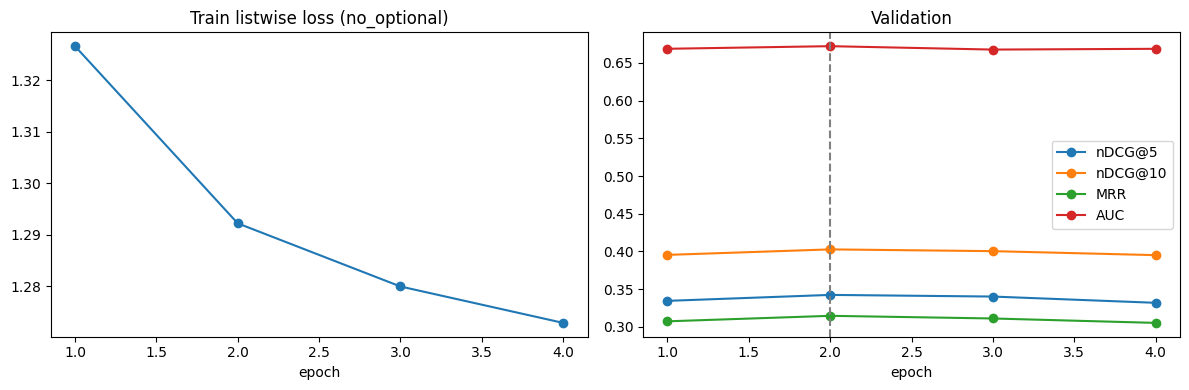

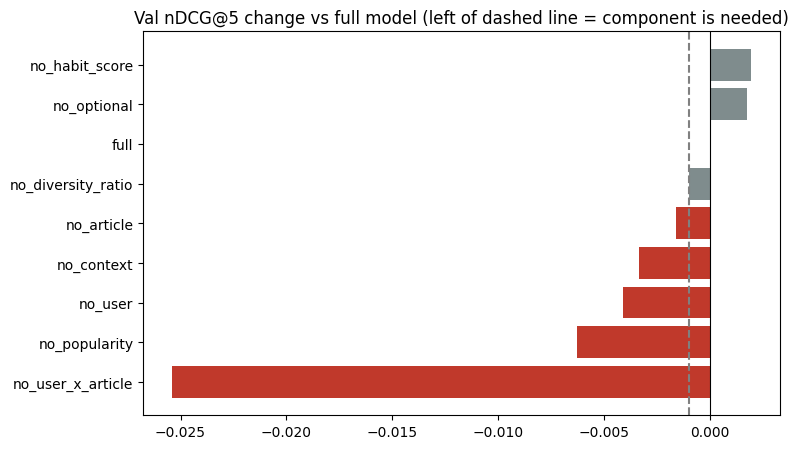

In [9]:
RUN_DIR = os.path.join(OUT_DIR, 'ablation_runs')
os.makedirs(RUN_DIR, exist_ok=True)
HPARAMS = {'embed_dim': EMBED_DIM, 'cat_dim': CAT_DIM, 'hidden': HIDDEN, 'dropout': DROPOUT, 'id_dropout': ID_DROPOUT,
           'lr': LR, 'weight_decay': WEIGHT_DECAY, 'batch_size': BATCH_SIZE, 'epochs': ABLATION_EPOCHS,
           'patience': PATIENCE, 'select_metric': SELECT_METRIC}
runs = {}          # config name -> {'cfg', 'component', 'seeds': [{seed, state, hist, metrics}]}


def run_experiment(cfg, component=None, seeds=ABLATION_SEEDS, verbose=False, cold_rate=COLD_SIM_RATE, register=True):
    """Train cfg once per seed (or reuse a saved identical run) and store it in `runs`."""
    out = []
    for sd in seeds:
        # runs with simulation get their own files; runs without it keep the original names/keys (reusable)
        tag = f"{cfg['name']}_seed{sd}" + (f"_coldsim{int(round(cold_rate * 100))}" if cold_rate > 0 else '')
        spec = {'cfg': cfg, 'seed': sd, 'hparams': HPARAMS}
        if cold_rate > 0:
            spec['cold_sim_rate'] = cold_rate
        key = json.dumps(spec, sort_keys=True)
        paths = {k: os.path.join(RUN_DIR, f'{tag}.{k}') for k in ['pt', 'csv', 'json']}
        t0 = time.time()
        if all(os.path.exists(p) for p in paths.values()) and open(paths['json']).read() == key:
            state = torch.load(paths['pt'], map_location='cpu')
            h = pd.read_csv(paths['csv'])
            how = 'reused saved run'
        else:
            m, h = train_model(cfg, epochs=ABLATION_EPOCHS, seed=sd, verbose=verbose, cold_rate=cold_rate)
            state = {k: v.detach().cpu() for k, v in m.state_dict().items()}
            torch.save(state, paths['pt']); h.to_csv(paths['csv'], index=False)
            with open(paths['json'], 'w') as f:
                f.write(key)
            how = f'trained in {(time.time() - t0) / 60:.1f} min'
        best_row = h.loc[h[f'val_{SELECT_METRIC}'].idxmax()]
        out.append({'seed': sd, 'state': state, 'hist': h, 'best_epoch': int(best_row['epoch']),
                    **{k: float(best_row[f'val_{k}']) for k in METRIC_NAMES}})
        print(f"{cfg['name']:28s} seed {sd} | cold sim {cold_rate:.0%} | best epoch {int(best_row['epoch'])} | "
              f"val nDCG@5 {best_row['val_nDCG@5']:.4f} | {how}")
    result = {'cfg': cfg, 'component': component, 'cold_rate': cold_rate, 'seeds': out}
    if register:
        runs[cfg['name']] = result
    return result


def val_score(name, metric=SELECT_METRIC):
    return float(np.mean([r[metric] for r in runs[name]['seeds']]))


# ── 1. Full model ──────────────────────────────────────────────────────────────
print('Full model features:')
for block, cols in active_features(FULL_CFG).items():
    print(f'  {block:15s}: {cols}')
run_experiment(FULL_CFG, verbose=True)

# ── 2. Leave-one-out ablation ─────────────────────────────────────────────────
if RUN_ABLATION:
    active_optional = [f for f in OPTIONAL_FEATURES if f not in FULL_CFG['drop']]
    ablation_cfgs = [(make_config(f'no_{f}', FULL_CFG['groups'], FULL_CFG['drop'] + [f]), ('feature', f))
                     for f in active_optional]
    if len(active_optional) > 1:
        ablation_cfgs.append((make_config('no_optional', FULL_CFG['groups'], FULL_CFG['drop'] + active_optional), None))
    ablation_cfgs += [(make_config(f'no_{g}', {**FULL_CFG['groups'], g: False}, FULL_CFG['drop']), ('group', g))
                      for g, on in FULL_CFG['groups'].items() if on]
    for cfg, comp in ablation_cfgs:
        run_experiment(cfg, component=comp)

    def ablation_row(name, removed=None):
        r = runs[name]
        vals = {k: np.mean([x[k] for x in r['seeds']]) for k in METRIC_NAMES}
        delta = vals[SELECT_METRIC] - val_score('full')
        comp = r['component']
        decision = '' if comp is None else ('drop' if delta >= -DROP_TOLERANCE else 'keep')
        if removed is None:
            removed = '-' if name == 'full' else (comp[1] if comp else ' + '.join(sorted(set(r['cfg']['drop']) - set(FULL_CFG['drop']))))
        return {'config': name, 'removed': removed, **{f'val_{k}': v for k, v in vals.items()},
                f'val_{SELECT_METRIC}_std': np.std([x[SELECT_METRIC] for x in r['seeds']]),
                f'delta_{SELECT_METRIC}': delta, 'decision': decision}

    ablation = pd.DataFrame([ablation_row(n) for n in runs])
    ablation.to_csv(os.path.join(OUT_DIR, 'ablation.csv'), index=False)
    print('\nAblation (validation; delta = config - full; "drop" = removing it does not hurt):')
    print(ablation.drop(columns=[f'val_{SELECT_METRIC}_std'] if len(ABLATION_SEEDS) == 1 else []).to_string(index=False))

    # ── 3. Reduced model: remove every component marked "drop" ───────────────
    to_drop = [runs[n]['component'] for n in ablation.loc[ablation.decision == 'drop', 'config']]
    drop_groups = [c[1] for c in to_drop if c[0] == 'group']
    drop_feats = [c[1] for c in to_drop if c[0] == 'feature']
    reduced_cfg = make_config('reduced', {**FULL_CFG['groups'], **{g: False for g in drop_groups}},
                              FULL_CFG['drop'] + drop_feats)
    print(f'\nComponents to drop: {drop_groups + drop_feats or "none"}')
    if not to_drop or not any(reduced_cfg['groups'].values()):
        BEST_NAME = 'full'
    else:
        matches = [n for n, r in runs.items() if r['cfg']['groups'] == reduced_cfg['groups']
                   and r['cfg']['drop'] == reduced_cfg['drop']]
        if matches:                                   # only one component dropped: already trained
            reduced_name = matches[0]
        else:
            run_experiment(reduced_cfg)
            reduced_name = 'reduced'
            ablation = pd.concat([ablation, pd.DataFrame([ablation_row('reduced', ' + '.join(drop_groups + drop_feats))])],
                                 ignore_index=True)
        # ── 4. Final choice on validation (simpler model preferred within tolerance) ─
        full_v, red_v = val_score('full'), val_score(reduced_name)
        BEST_NAME = reduced_name if red_v >= full_v - DROP_TOLERANCE else 'full'
        print(f'val {SELECT_METRIC}: full {full_v:.4f} | {reduced_name} {red_v:.4f}')
    ablation['selected'] = ablation['config'] == BEST_NAME
    ablation.to_csv(os.path.join(OUT_DIR, 'ablation.csv'), index=False)
else:
    BEST_NAME = 'full'

BEST_CFG = runs[BEST_NAME]['cfg']
print(f'\n>>> Selected model: {BEST_NAME}')
for block, cols in active_features(BEST_CFG).items():
    print(f'  {block:15s}: {cols}')
print('  groups on      :', [g for g, on in BEST_CFG['groups'].items() if on])

# load the selected model (first seed) for evaluation
best_run = runs[BEST_NAME]['seeds'][0]
model = build_model(BEST_CFG)
model.load_state_dict(best_run['state'])
hist, best_ep = best_run['hist'], best_run['best_epoch']
torch.save(model.state_dict(), os.path.join(OUT_DIR, f'{MODEL_NAME}_best.pt'))
hist.to_csv(os.path.join(OUT_DIR, 'training_history.csv'), index=False)

try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(hist.epoch, hist.train_loss, marker='o'); ax[0].set_title(f'Train listwise loss ({BEST_NAME})'); ax[0].set_xlabel('epoch')
    for k in ['val_nDCG@5', 'val_nDCG@10', 'val_MRR', 'val_AUC']:
        ax[1].plot(hist.epoch, hist[k], marker='o', label=k[4:])
    ax[1].axvline(best_ep, ls='--', c='grey'); ax[1].set_title('Validation'); ax[1].set_xlabel('epoch'); ax[1].legend()
    plt.tight_layout(); plt.show()
    if RUN_ABLATION:
        ab = ablation.sort_values(f'delta_{SELECT_METRIC}')
        plt.figure(figsize=(8, 0.4 * len(ab) + 1))
        plt.barh(ab.config, ab[f'delta_{SELECT_METRIC}'],
                 color=['#c0392b' if d == 'keep' else '#7f8c8d' for d in ab.decision])
        plt.axvline(-DROP_TOLERANCE, ls='--', c='grey'); plt.axvline(0, c='black', lw=0.8)
        plt.title(f'Val {SELECT_METRIC} change vs full model (left of dashed line = component is needed)')
        plt.tight_layout(); plt.show()
except ImportError:
    pass

## 8. Evaluation of the selected model: validation & test (overall + cold-start slices)

In [10]:
def print_test_population(Ad, label):
    hl, users = Ad['hist_len'], Ad['user_id']
    print(f"{label}: {len(hl):,} impressions from {pd.unique(users).size:,} unique users | "
          f"cold users {pd.unique(users[hl == 0]).size:,} ({(hl == 0).sum():,} impressions) | "
          f"sparse users {pd.unique(users[(hl > 0) & (hl < SPARSE_MAX)]).size:,} | "
          f"warm users {pd.unique(users[hl >= SPARSE_MAX]).size:,}")


for split in ['val', 'test']:
    print_test_population(A[split], f'Evaluating on {split}')
print()

results, scores_by_split = [], {}
for split in ['val', 'test']:
    sc = predict(model, A[split])
    scores_by_split[split] = sc
    table, _ = evaluate(A[split], sc)
    table.insert(0, 'config', BEST_NAME); table.insert(0, 'split', split); table.insert(0, 'model', MODEL_NAME)
    results.append(table)
    write_outputs(A[split], sc)
metrics = pd.concat(results, ignore_index=True)
metrics.to_csv(os.path.join(OUT_DIR, 'metrics.csv'), index=False)
metrics.to_json(os.path.join(OUT_DIR, 'metrics.json'), orient='records', indent=2)
pd.set_option('display.float_format', '{:.4f}'.format)
print(metrics.to_string(index=False))

Evaluating on val: 30,270 impressions from 20,179 unique users | cold users 476 (772 impressions) | sparse users 2,657 | warm users 17,046
Evaluating on test: 73,152 impressions from 50,000 unique users | cold users 1,407 (2,214 impressions) | sparse users 6,607 | warm users 41,986

model split      config        slice  n_impressions  n_users    AUC    MRR  nDCG@5  nDCG@10  Recall@5  Recall@10
  mlp   val no_optional          all          30270    20179 0.6720 0.3148  0.3425   0.4028    0.4696     0.6416
  mlp   val no_optional    cold_user            772      476 0.5815 0.2379  0.2512   0.3061    0.3723     0.5292
  mlp   val no_optional  sparse_user           3247     2657 0.6100 0.3001  0.3174   0.3747    0.4575     0.6256
  mlp   val no_optional    warm_user          26251    17046 0.6823 0.3188  0.3483   0.4091    0.4740     0.6469
  mlp   val no_optional cold_article          22543    16161 0.6647 0.3335  0.3606   0.4173    0.4984     0.6624
  mlp  test no_optional          all  

### 8.1 Reference baselines on the same test set
Same metrics, same slates:
* `popularity_ctr`: lagged `hist_ctr` only · `random`: random scores
* `mlp_no_cold_sim`: the selected config trained **without** cold-user simulation (reuses the saved run if it exists). This shows what the simulation changed, especially on `cold_user`.
* `mlp_pop_fallback`: the selected model for warm users, plain CTR ranking for cold users (a rule-based hybrid, for reference)

The `cold_user` row is the key check from Section 2.1: before the simulation, the MLP was below `popularity_ctr` there.

In [11]:
rng = np.random.default_rng(SEED)
ctr_col = CAND_COLS.index('hist_ctr')
base = []
print_test_population(A['test'], 'Testing on')
At = A['test']
ctr = At['cand_x'][:, ctr_col]
cold_row = np.repeat(At['hist_len'] == 0, At['n'])
contenders = [('popularity_ctr', ctr), ('random', rng.random(len(At['news'])).astype(np.float32)),
              ('mlp_pop_fallback', np.where(cold_row, ctr, scores_by_split['test']))]
if COMPARE_NO_SIM and COLD_SIM_RATE > 0:
    nosim = run_experiment(BEST_CFG, seeds=[ABLATION_SEEDS[0]], cold_rate=0.0, register=False)
    m_nosim = build_model(BEST_CFG); m_nosim.load_state_dict(nosim['seeds'][0]['state'])
    contenders.insert(0, ('mlp_no_cold_sim', predict(m_nosim, At)))
    del m_nosim
for name, sc in contenders:
    t, _ = evaluate(At, sc)
    t.insert(0, 'split', 'test'); t.insert(0, 'model', name)
    base.append(t)
compare = pd.concat([metrics[metrics.split == 'test']] + base, ignore_index=True)
order = ['all', 'cold_user', 'sparse_user', 'warm_user', 'cold_article']
print('\nTest population per slice:')
print(base[0][['slice', 'n_impressions', 'n_users']].to_string(index=False))
print('\nTest nDCG@5 by slice:')
print(compare.pivot(index='slice', columns='model', values='nDCG@5').loc[order, [MODEL_NAME] + [n for n, _ in contenders]].round(4).to_string())
print('\nAll metrics, real cold users only (test):')
print(compare[compare.slice == 'cold_user'].drop(columns=['split', 'slice', 'config'], errors='ignore').round(4).to_string(index=False))
compare.to_csv(os.path.join(OUT_DIR, 'test_vs_baselines.csv'), index=False)

Testing on: 73,152 impressions from 50,000 unique users | cold users 1,407 (2,214 impressions) | sparse users 6,607 | warm users 41,986
no_optional                  seed 42 | cold sim 0% | best epoch 2 | val nDCG@5 0.3412 | reused saved run

Test population per slice:
       slice  n_impressions  n_users
         all          73152    50000
   cold_user           2214     1407
 sparse_user           8092     6607
   warm_user          62846    41986
cold_article          42682    32082

Test nDCG@5 by slice:
model           mlp  mlp_no_cold_sim  popularity_ctr  random  mlp_pop_fallback
slice                                                                         
all          0.3600           0.3585          0.2834  0.2228            0.3602
cold_user    0.2784           0.2613          0.2828  0.2375            0.2828
sparse_user  0.3613           0.3527          0.3337  0.2647            0.3613
warm_user    0.3627           0.3626          0.2769  0.2168            0.3627
cold_article

## 9. Save run configuration

In [12]:
run_config = {
    'model': MODEL_NAME, 'feature_dir': FEATURE_DIR, 'selected_config': BEST_NAME, 'best_epoch': best_ep,
    'hyperparameters': {**HPARAMS, 'seed': ABLATION_SEEDS[0]},
    'selected_groups': BEST_CFG['groups'], 'dropped_features': BEST_CFG['drop'],
    'selected_features': active_features(BEST_CFG),
    'ablation': {'run': RUN_ABLATION, 'seeds': ABLATION_SEEDS, 'drop_tolerance': DROP_TOLERANCE,
                 'configs': list(runs)},
    'cold_user_simulation': {'rate': COLD_SIM_RATE, 'applies_to': 'training batches only (all runs)'},
    'contract': {k: meta[k] for k in ['split', 'negative_sampling', 'cold_start', 'leakage', 'excluded_features']},
}
with open(os.path.join(OUT_DIR, 'run_config.json'), 'w') as f:
    json.dump(run_config, f, indent=2, default=str)
print('Outputs:', sorted(os.listdir(OUT_DIR)))

Outputs: ['ablation.csv', 'ablation_runs', 'ablation_test.csv', 'metrics.csv', 'metrics.json', 'mlp_best.pt', 'permutation_importance.csv', 'prediction_test.txt', 'prediction_val.txt', 'predictions_test.parquet', 'predictions_val.parquet', 'run_config.json', 'test_vs_baselines.csv', 'topk_test.csv', 'topk_val.csv', 'training_history.csv']
